# Robustness of Document Layout Analysis Under Compound Degradation
## Results walkthrough, phase by phase

| | |
|---|---|
| **Course** | Data Science Tools & Techniques |
| **Instructor** | Dr. Muhammad Mateen Yaqoob |
| **Programme** | MS Data Science, FAST-NUCES Islamabad, Fall 2026 |
| **Students** | Khizar Mohammad Hashmi (26I-8009), Alishba Abbas (26I-8032) |
| **Repository** | https://github.com/KhizarHashmi/RDLD_Project |
| **Research paper** | *Robustness of Document Layout Analysis Under Compound Degradation* (IEEE conference format) |

**What this notebook is.** We did all of the work with the Python scripts in `scripts/`, on our own machine, and each
script saved its tables and figures to a results folder. Nothing is re-run here. The notebook goes through the phases in
the order we ran them, and for each phase it shows who did it, the main part of the code, and what it produced. The
cells only read the saved result files, so they take a few seconds and need no GPU, and the outputs are saved in the
notebook, so it can be read on GitHub as it is.

## How the work was organised

The study asks three research questions on 300 DocLayNet pages from the validation split and 300 from the official test
split, with eleven layout detectors and 109 image conditions per page set:

- **RQ1.** Do document degradations combine additively, or do they compound?
- **RQ2.** Does mAP predict the quality of the text a downstream reader extracts?
- **RQ3.** Are clean-condition detector rankings preserved under single and compound degradation?

Each phase was split into a Khizar part and an Alishba part of similar size (`docs/phases/PHASE_PLAN.md`). The two
parts meet in the shared data folder: Alishba's scripts produce pages, degraded images and image-level and text-level
measurements, and Khizar's scripts produce detections, detection-level measurements and the statistics. Each person
committed their own scripts and phase notes from their own branch, and both branches were then merged into `main`.

| Phase | Data science life-cycle stage | Khizar | Alishba |
|---|---|---|---|
| P0 Feasibility and data | Problem framing, data acquisition | Detector feasibility, figures | Degradation and composition feasibility, stratified DocLayNet extraction |
| P1 Clean baseline | Data validation, exploratory analysis, baseline model | Detector wrappers, clean mAP | Corpus validation, EDA |
| P2 Pipeline | Data preparation, model inference, evaluation | Batch inference, mAP and mRD evaluator | Composition engine, degraded-image cache, image-quality metrics |
| P3 Main experiment (RQ1) | Statistical analysis | Bootstrap, interaction terms, RQ1 analysis | Image quality versus accuracy, composition-order check |
| P4 Rankings and per-region (RQ3) | Statistical analysis, error analysis | Ranking stability, seeds, significance tests | Per-class AP, structural error rates |
| P5 Downstream link (RQ2) | Evaluation against the end use | Weighted mAP, mAP versus downstream | OCR pipeline, WER and text measures |
| P6 Results | Communication | Results synthesis and paper | Results synthesis and paper |
| P7 Extension and checks | Validation of the findings | More detectors, RF-DETR fine-tuning, checks | RF-DETR training data, test-split pages |

## The pipeline

This is Fig. 1 of the paper. Data is sampled and checked, every page is degraded under 109 conditions, each degraded
image is measured three ways (image damage, detection, OCR), and the scores answer the three questions. The same chain
ran, unchanged, on both page sets.

validation page set: RDLD_data   test page set: RDLD_data_test   (next to the repository)


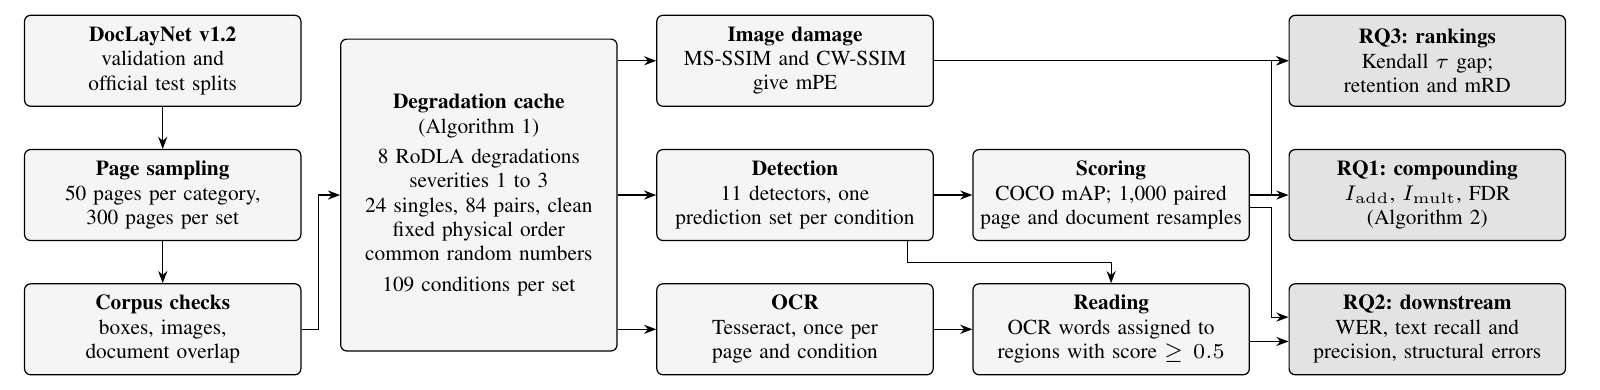

In [1]:
import io, os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as IPImage

# data folders sit next to the repository; set RDLD_DATA to point elsewhere
DATA = Path(os.getenv("RDLD_DATA", "../../RDLD_data")).resolve()
TEST = DATA.parent / "RDLD_data_test"
R, RT = DATA / "results", TEST / "results"
RD, RTD = DATA.parent / "RDLD_data_docboot" / "results", DATA.parent / "RDLD_data_test_docboot" / "results"
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

MODELS = ["yolo", "yolo26l", "yolo11m", "yolo11l", "heron", "heron101", "egret", "egretxl", "detr", "ddetr", "rfdetr"]
NAME = {"yolo": "YOLO26-m", "yolo26l": "YOLO26-l", "yolo11m": "YOLOv11-m", "yolo11l": "YOLOv11-l", "heron": "Heron",
        "heron101": "Heron-101", "egret": "Egret-m", "egretxl": "Egret-xl", "detr": "DETR",
        "ddetr": "Deformable DETR", "rfdetr": "RF-DETR"}


def show(path, width=900, photo=False, max_side=1600):
    """Display a saved figure, scaled down so the notebook stays small."""
    im = Image.open(path)
    im.thumbnail((max_side, max_side * 4))
    buf = io.BytesIO()
    if photo:
        im.convert("RGB").save(buf, "JPEG", quality=80)
    else:
        im.save(buf, "PNG", optimize=True)
    display(IPImage(data=buf.getvalue(), width=width))


def named(df, col="model"):
    df = df.copy()
    df[col] = df[col].map(NAME).fillna(df[col])
    return df


print("validation page set:", DATA.name, "  test page set:", TEST.name, "  (next to the repository)")
show("assets/pipeline.png", width=1000)

In [2]:
# scale of what was run: pages, conditions, cached images and prediction files on disk
for name, root in [("validation", DATA), ("test", TEST)]:
    man = pd.read_csv(root / "doclaynet" / "manifest.csv", dtype={"id": str})
    cfg = pd.read_csv(root / "degraded" / "configs.csv")
    n_img = sum(len(os.listdir(root / "degraded" / c)) for c in cfg.config if c != "clean")
    n_pred = sum(1 for m in MODELS for _ in (root / "predictions" / m).glob("*.json"))
    print(f"{name:10s}  pages {len(man)}  documents {man.original_filename.nunique():3d}  conditions {len(cfg)}  "
          f"degraded images {n_img:,}  prediction files {n_pred:,}")

validation  pages 300  documents  23  conditions 109  degraded images 32,400  prediction files 1,903
test        pages 300  documents  44  conditions 109  degraded images 32,400  prediction files 1,199


---
## P0. Feasibility and data

**Life-cycle stage:** problem framing and data acquisition.

| Part | By | Scripts |
|---|---|---|
| Stratified DocLayNet extraction, both splits | Alishba | `p0_prepare_doclaynet.py` |
| Degradation and composition feasibility | Alishba | `p0_verify_perturbations.py`, `rdld/degradations.py` |
| Detector feasibility (do the detectors load and run) | Khizar | `p0_detector_gate.py`, `rdld/detectors.py` |
| Explanatory figures | Khizar | `p0_make_figures.py` |

The first question was whether the RoDLA degradations, which were written to be applied one at a time, can be applied
on top of each other at all. All 28 pairs of the eight image-only degradations composed (tested at severity 2), and so did
five sampled triples. DocLayNet's
data files are sorted by category, so the pages were drawn by reading across all files until each of the six document
categories had 50 pages.

`scripts/p0_prepare_doclaynet.py`, lines 60–76 (stratified sampling across the sorted data files)

```python
for sp in shards:
    if all(taken[c] >= N_PER_CAT for c in
           ["financial_reports", "scientific_articles", "government_tenders",
            "laws_and_regulations", "manuals", "patents"]):
        break

    shard_name = sp.split(f"{SPLIT}-")[1][:5]
    print(f"--- shard {shard_name}")
    tbl = pq.read_table(sp, columns=["image", "bboxes", "category_id",
                                     "area", "metadata"])
    rows = tbl.to_pylist()

    for r in rows:
        cat = r["metadata"]["doc_category"]
        if taken[cat] >= N_PER_CAT:
            continue
        if not r["category_id"]:          # skip pages with no annotations
```

`rdld/degradations.py`, lines 55–68 (every degradation call is seeded from (degradation, severity, page, replicate))

```python
def seed_for(name, severity, page_id, rep=0):
    h = hashlib.md5(f"{name}|{severity}|{page_id}|{rep}".encode()).hexdigest()
    return int(h[:8], 16)


def apply_one(img, name, severity, page_id, rep=0):
    """One degradation, deterministic given (name, severity, page, rep). img: BGR uint8."""
    s = seed_for(name, severity, page_id, rep)
    np.random.seed(s)
    random.seed(s)
    out = _fn(name)(img.copy(), degree=severity)
    if out.shape != img.shape:
        raise ValueError(f"{name}@{severity} changed shape {img.shape} -> {out.shape}")
    return out
```

In [3]:
# the composition test from the feasibility log
log = (R / "p0" / "logs" / "p0_verify_perturbations.log").read_text(encoding="utf8").splitlines()
print("\n".join(l for l in log if "COMPOSABLE" in l or "[PASS]" in l))

# pages per category in both page sets
both = pd.concat([pd.read_csv(r / "doclaynet" / "manifest.csv").assign(page_set=n) for n, r in [("validation", DATA), ("test", TEST)]])
both.pivot_table(index="doc_category", columns="page_set", values="id", aggfunc="count")

  COMPOSABLE : 28/28 pairs
  [PASS] >=6 perturbations work standalone      (8)
  [PASS] >=80% of pairs compose                  (28/28)
  [PASS] triples compose                          (5/5)


page_set,test,validation
doc_category,,
financial_reports,50,50
government_tenders,50,50
laws_and_regulations,50,50
manuals,50,50
patents,50,50
scientific_articles,50,50


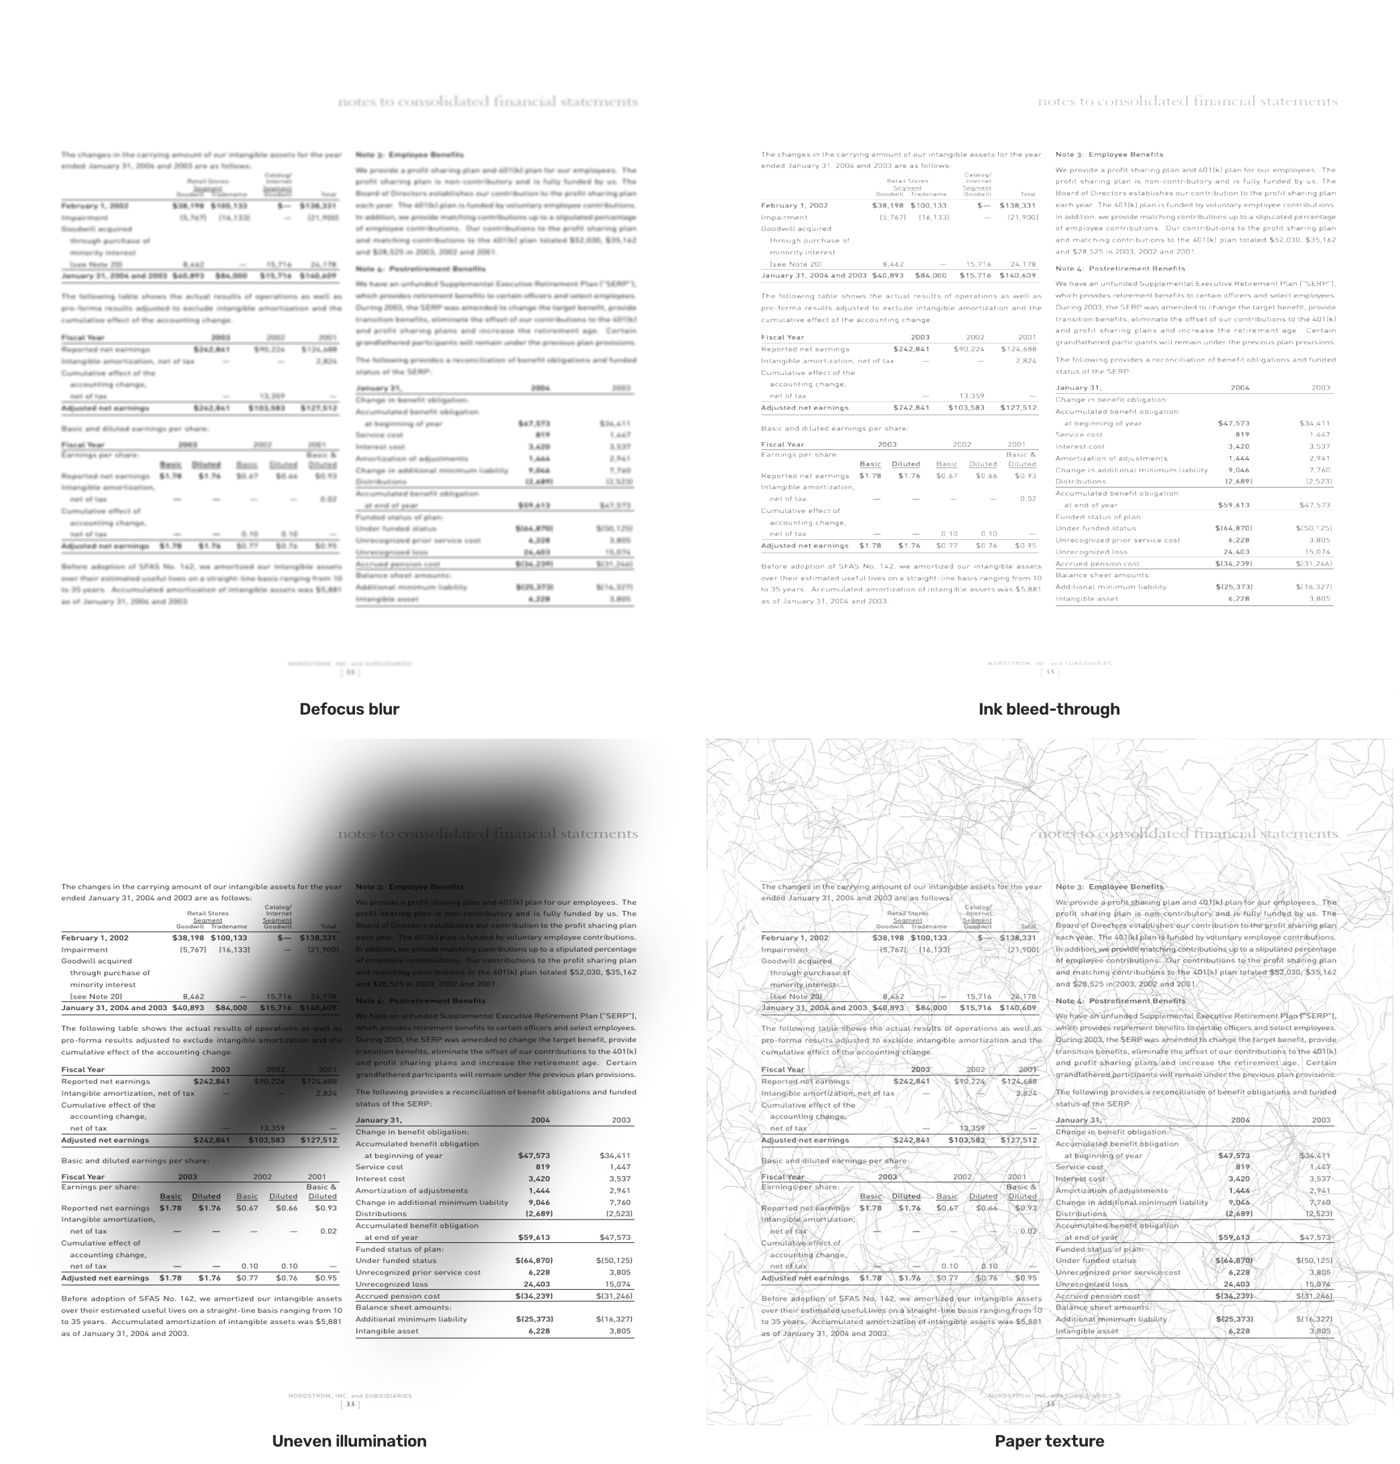

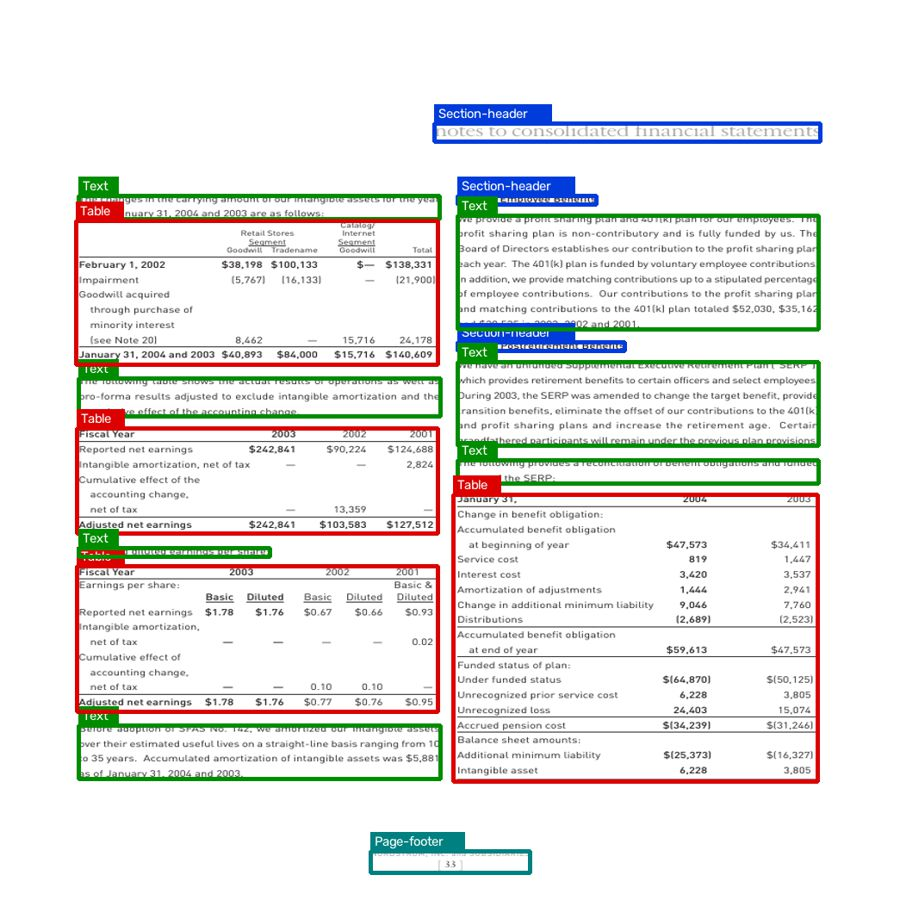

In [4]:
# four of the eight degradations on one page (defocus, ink bleeding, uneven illumination, paper texture), and the ground-truth boxes of a page
show(R / "p0" / "figures" / "fig_degradation_grid.png", width=900, photo=True, max_side=1400)
show(R / "p0" / "figures" / "fig_gt_boxes.png", width=520, photo=True, max_side=900)

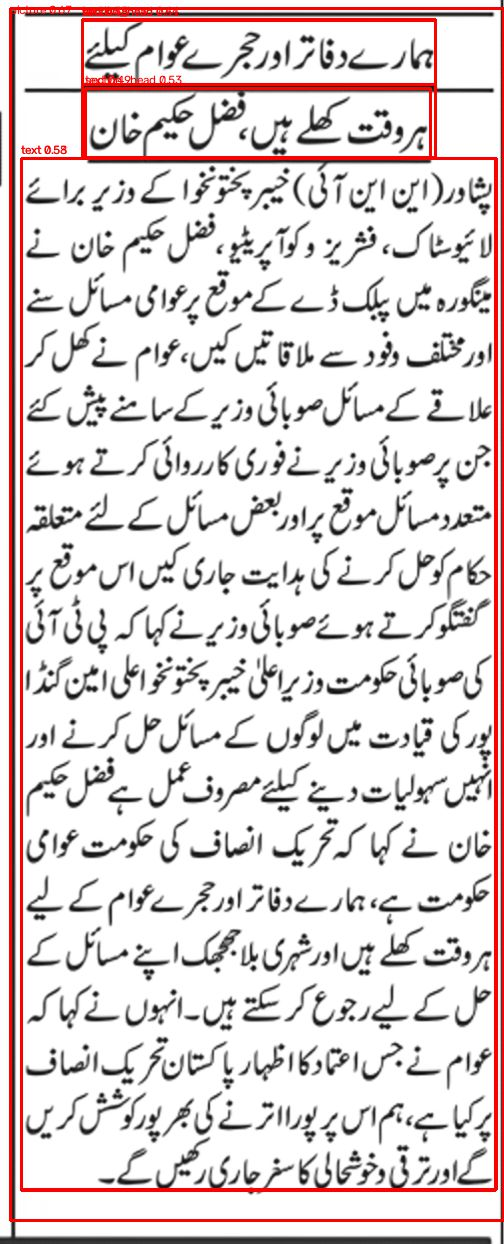

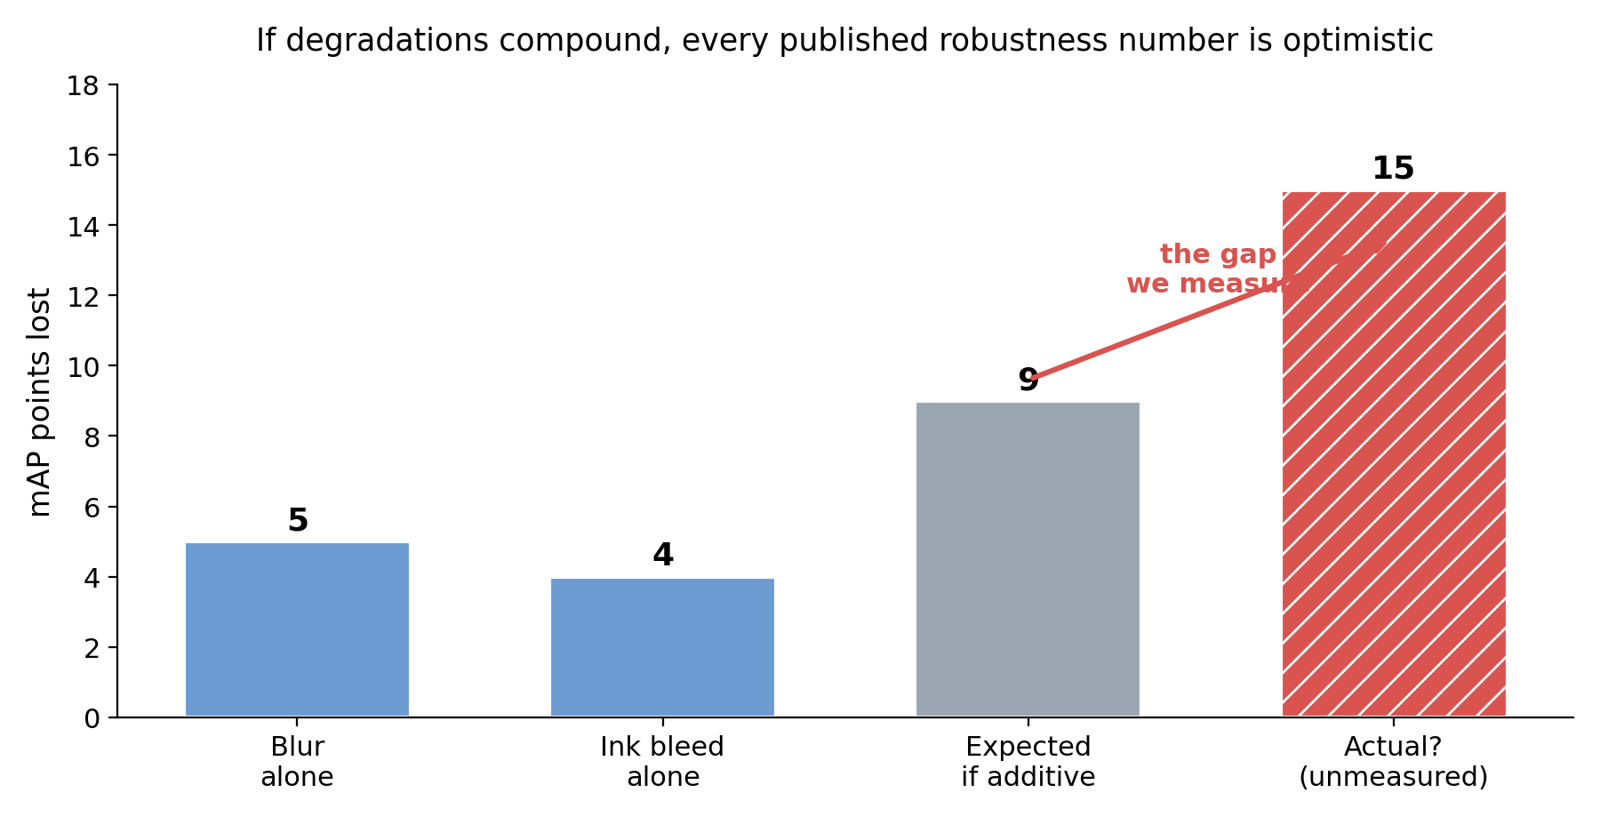

In [5]:
# feasibility gate: the Heron detector run on a sample newspaper page, only to check that it loads and predicts;
# then the idea of an interaction
show(R / "p0" / "detections" / "ds4sd_docling-layout-heron.png", width=300, photo=True, max_side=1000)
show(R / "p0" / "figures" / "fig_interaction_concept.png", width=800)

---
## P1. Clean baseline

**Life-cycle stage:** data validation, exploratory analysis and the baseline model.

| Part | By | Scripts |
|---|---|---|
| Corpus validation (boxes, images, classes) | Alishba | `p1_validate_corpus.py` |
| Exploratory data analysis | Alishba | `p1_eda.py` |
| Detector wrappers, class mapping and clean mAP | Khizar | `p1_clean_baseline.py`, `rdld/detectors.py`, `rdld/evaluation.py` |

Before degrading anything, the pages were checked and described, and every detector was scored on the clean pages.

`scripts/p1_validate_corpus.py`, lines 39–60 (every check is recorded as PASS or WARN)

```python
def check(name, ok, detail):
    checks.append({"check": name, "status": "PASS" if ok else "WARN", "detail": detail})
    print(f"  [{'PASS' if ok else 'WARN'}] {name:44s} {detail}")


print("=" * 70)
print(" P1 CORPUS VALIDATION")
print("=" * 70)

# ---------------------------------------------------------------- images
im_by = {im["id"]: im for im in gt["images"]}
bad_open, bad_size, modes = [], [], Counter()
for im in gt["images"]:
    p = config.IMAGES / im["file_name"]
    try:
        with Image.open(p) as f:
            modes[f.mode] += 1
            if f.size != (im["width"], im["height"]):
                bad_size.append(im["file_name"])
    except Exception as e:                        # noqa: BLE001 - report any failure
        bad_open.append(f"{im['file_name']}: {type(e).__name__}")
check("images open", not bad_open, f"{len(gt['images']) - len(bad_open)}/{len(gt['images'])}")
```

In [6]:
pd.read_csv(R / "p1" / "validation" / "checks.csv")

,check,status,detail
0,images open,PASS,300/300
1,image size matches COCO record,PASS,0 mismatches
2,image ids unique,PASS,300 unique
3,single page size,PASS,"{(1025, 1025): 300}; modes {'RGB': 300}"
4,boxes inside page (+/-1 px),WARN,1/3530 outside
5,boxes have positive size,PASS,0/3530 degenerate
6,class ids in 1..11,PASS,0 invalid
7,stored area ~= box w*h,PASS,"area/(w*h): median 1.000, min 1.000, max 1.000"
8,every page has annotations,PASS,0 empty pages
9,no exact duplicate GT boxes,PASS,0 pairs


In [7]:
pd.read_csv(R / "p1" / "eda" / "summary_by_category.csv")

,doc_category,pages,regions_mean,regions_sd,classes_mean,tables,pictures,coverage_mean,ink_ratio_mean,colourful_pages
0,financial_reports,50,12.32,14.811,3.88,40,63,0.438,0.063,17
1,scientific_articles,50,9.34,3.998,3.50,6,11,0.407,0.020,0
2,government_tenders,50,10.46,4.057,3.64,37,3,0.323,0.044,1
3,laws_and_regulations,50,8.30,3.303,4.12,7,15,0.418,0.051,4
4,manuals,50,19.58,7.228,4.08,5,0,0.301,0.030,1
5,patents,50,10.60,4.347,2.76,7,27,0.474,0.072,0


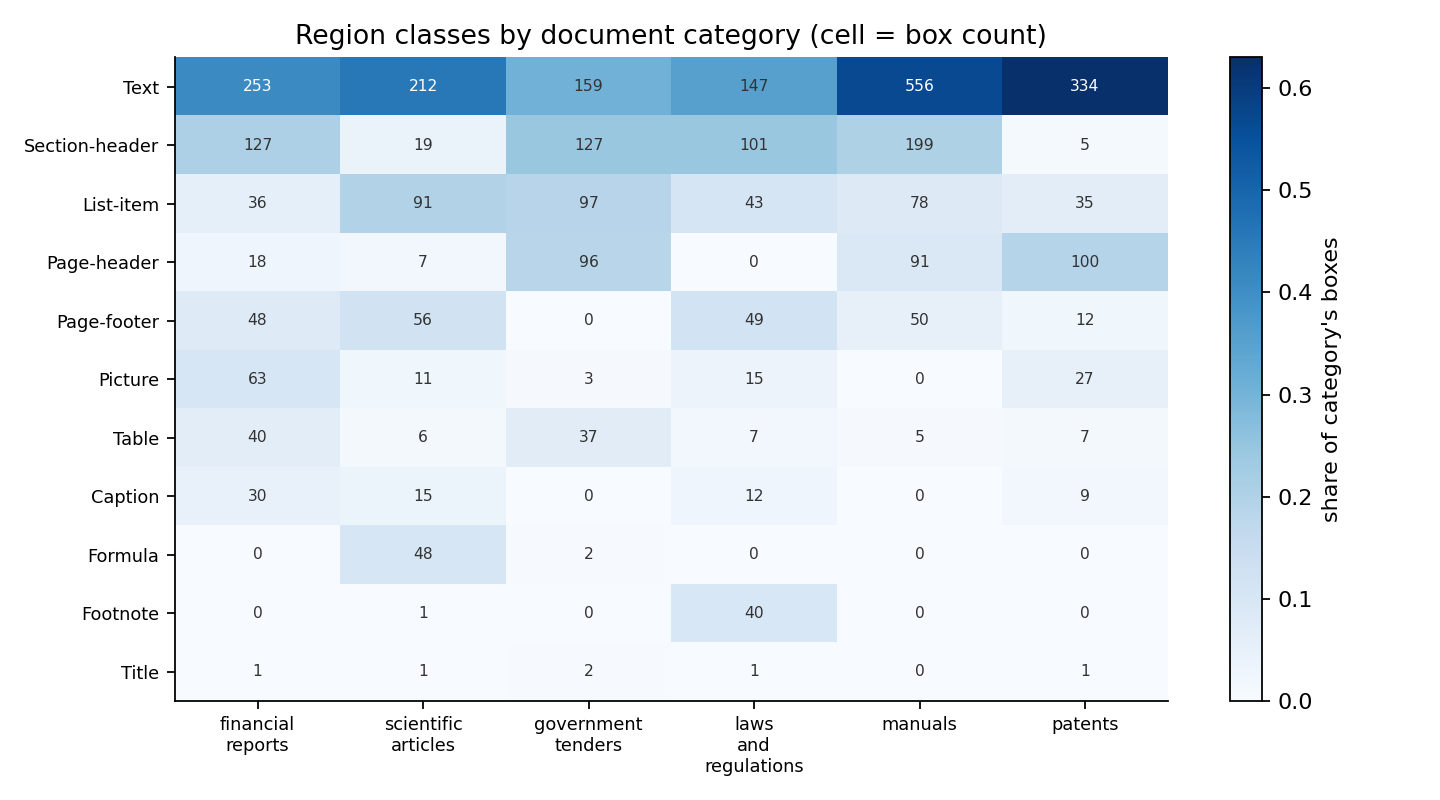

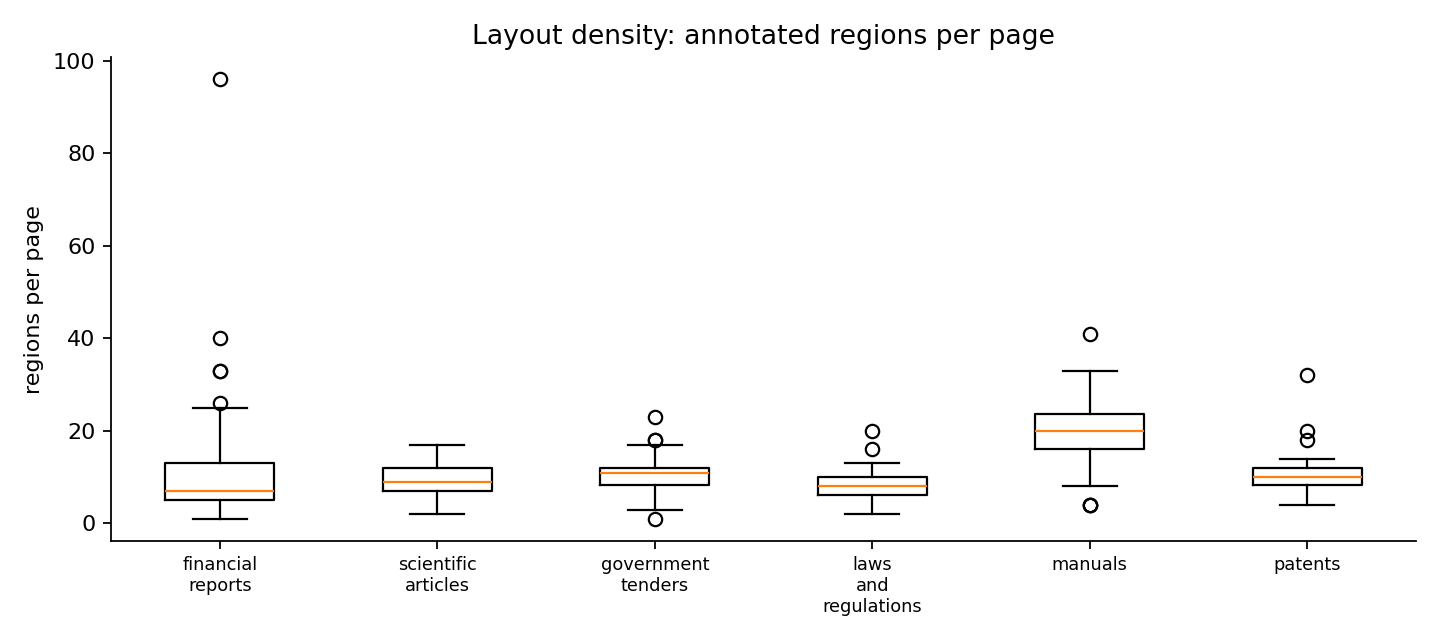

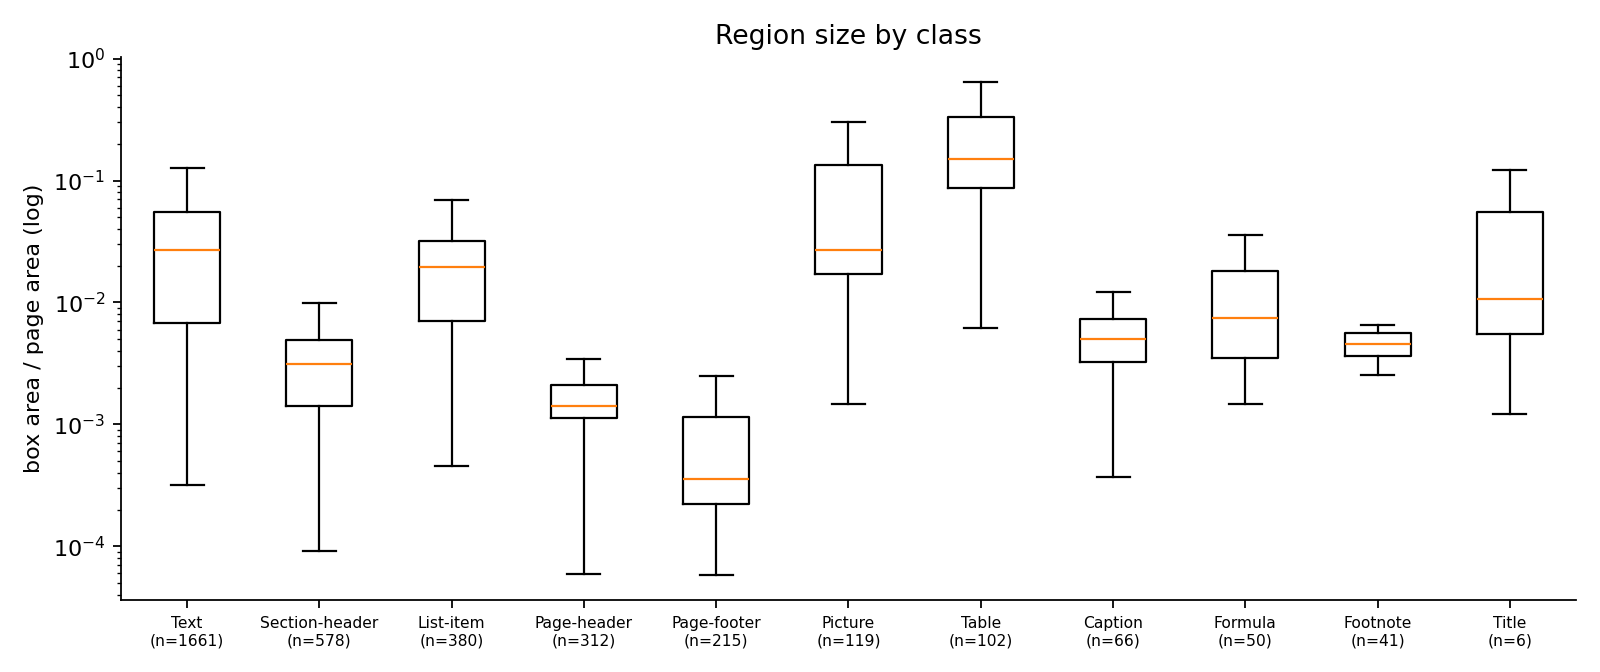

In [8]:
show(R / "p1" / "eda" / "fig_class_by_category.png", width=820)
show(R / "p1" / "eda" / "fig_regions_per_page.png", width=760)
show(R / "p1" / "eda" / "fig_box_size_by_class.png", width=820)

**Clean accuracy.** The cell below recomputes Table I of the paper from the saved files: the mAP of each detector on the
clean pages, and its 95% interval from the 1,000 page resamples (row 0 of each bootstrap table is the full sample).

In [9]:
def clean_table(root):
    out = []
    for m in MODELS:
        a = np.load(root / "p3" / "boot" / m / "clean.npy")          # (1001 rows, 11 classes): full sample, then resamples
        v = 100 * np.nanmean(a, axis=1)
        lo, hi = np.percentile(v[1:], [2.5, 97.5])
        out.append((NAME[m], round(v[0], 1), f"[{lo:.1f}, {hi:.1f}]"))
    return pd.DataFrame(out, columns=["detector", "mAP", "95% CI"]).set_index("detector")

clean_table(R).join(clean_table(RT), lsuffix=" (validation)", rsuffix=" (test)")

,mAP (validation),95% CI (validation),mAP (test),95% CI (test)
detector,,,,
YOLO26-m,68.8,"[64.2, 72.4]",71.4,"[68.2, 74.9]"
YOLO26-l,68.2,"[63.4, 72.1]",73.1,"[69.6, 76.7]"
YOLOv11-m,68.9,"[64.8, 72.4]",71.3,"[67.7, 74.9]"
YOLOv11-l,69.4,"[66.7, 72.4]",72.5,"[68.6, 76.0]"
Heron,64.2,"[60.6, 68.5]",65.7,"[62.7, 69.3]"
Heron-101,65.9,"[62.3, 70.3]",66.1,"[63.2, 69.6]"
Egret-m,61.5,"[57.9, 65.9]",64.4,"[61.4, 68.1]"
Egret-xl,62.3,"[58.3, 66.9]",63.9,"[61.0, 67.6]"
DETR,53.0,"[49.2, 57.2]",41.3,"[38.9, 45.2]"


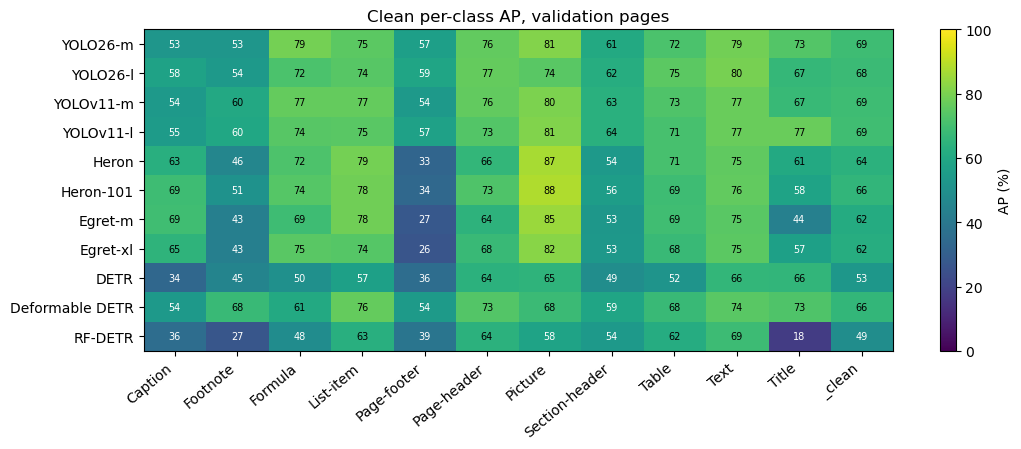

In [10]:
# per-class AP on clean validation pages: which region types are hard before any damage
ml = pd.read_csv(R / "p2" / "evaluation" / "metrics_long.csv")
ap = ml[ml.config == "clean"].set_index("model").filter(like="AP_").drop(columns=["AP_small", "AP_medium", "AP_large"])
ap.columns = [c[3:] for c in ap.columns]
ap = (100 * ap.loc[MODELS]).rename(index=NAME)
fig, ax = plt.subplots(figsize=(11, 4.6))
im = ax.imshow(ap.values, cmap="viridis", aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(ap.shape[1]), ap.columns, rotation=40, ha="right"); ax.set_yticks(range(len(ap)), ap.index)
for i in range(ap.shape[0]):
    for j in range(ap.shape[1]):
        ax.text(j, i, f"{ap.values[i, j]:.0f}", ha="center", va="center", fontsize=7, color="w" if ap.values[i, j] < 60 else "k")
fig.colorbar(im, ax=ax, label="AP (%)"); ax.set_title("Clean per-class AP, validation pages"); plt.tight_layout(); plt.show()

---
## P2. Pipeline

**Life-cycle stage:** data preparation (the degraded images), model inference and evaluation.

| Part | By | Scripts |
|---|---|---|
| Composition engine and degraded-image cache | Alishba | `rdld/degradations.py`, `p2_generate_cache.py` |
| Image-quality metrics (PSNR, MS-SSIM, CW-SSIM, mPE) | Alishba | `p2_image_quality.py`, `rdld/image_quality.py` |
| Batch inference over the cache | Khizar | `p2_run_inference.py` |
| mAP, mPE and mRD evaluator | Khizar | `p2_evaluate.py`, `rdld/evaluation.py` |

Every page was degraded under 109 conditions (clean, 24 singles, 84 same-severity pairs), the eleven detectors ran on
every image, and every prediction file was scored. A pair A+B is made by applying B to the cached image of the single A,
with the same seeds, so the pair differs from the single only by the added degradation (Algorithm 1 in the paper).

`scripts/p2_generate_cache.py`, lines 38–55 (a pair starts from the cached single)

```python
def _job(args):
    from rdld import degradations as D
    cfg, kind, a, sev, page_id, fname = args
    dst = config.DEGRADED / cfg / fname
    if dst.exists():
        return cfg, 0.0, "skip"
    t0 = time.time()
    if kind == "single":
        img = D.apply_one(cv2.imread(str(config.IMAGES / fname)), a, sev, page_id)
    else:                                    # pair: start from cached single A
        first = config.DEGRADED / D.config_id([(a, sev)]) / fname
        img = cv2.imread(str(first))
        if img is None:
            raise FileNotFoundError(first)
        b = [n for n, _ in D.steps_of(cfg) if n != a][0]
        img = D.apply_one(img, b, sev, page_id)
    cv2.imwrite(str(dst), img, PNG)
    return cfg, time.time() - t0, "done"
```

`rdld/image_quality.py`, lines 78–82 (image damage per page)

```python
def all_metrics(x, y):
    """x clean, y degraded: (N,3,H,W) float 0..255. Returns dict of (N,) tensors."""
    return {"psnr": psnr(x, y),
            "ms_ssim": ms_ssim(x, y, data_range=255, size_average=False),
            "cw_ssim": cw_ssim(x, y)}
```

`scripts/p2_evaluate.py`, lines 38–59 (COCO mAP per prediction file, and RoDLA's mRD)

```python
def _score(args):
    global _gt
    from rdld import evaluation
    if _gt is None:
        _gt = load_coco()
    model, cfg = args
    dets = json.loads((config.PREDICTIONS / model / f"{cfg}.json").read_text(encoding="utf-8"))
    r = evaluation.coco_map(_gt, dets)
    row = {"model": model, "config": cfg, "n_dets": len(dets)}
    row.update({k: r[k] for k in ("mAP", "mAP50", "mAP75", "AP_small", "AP_medium", "AP_large")})
    row.update({f"AP_{c}": v for c, v in r["per_class"].items()})
    return row


def rd_table(M, iq):
    """RoDLA Eq. 4 with mPE_IQA, per model and single degradation."""
    s = M[M.kind == "single"].merge(iq[["config", "mPE_iqa"]], on="config")
    s = s[s.mPE_iqa >= 1.0]
    s["err_over_mpe"] = (100 - 100 * s.mAP) / s.mPE_iqa
    rd = s.groupby(["model", "a"]).err_over_mpe.mean().rename("RD").reset_index()
    mrd = rd.groupby("model").RD.mean().rename("mRD").reset_index()
    return rd, mrd
```

In [11]:
cfg = pd.read_csv(DATA / "degraded" / "configs.csv")
cfg.groupby(["kind", "severity"]).size().unstack(fill_value=0)

severity,0,1,2,3
kind,,,,
clean,1,0,0,0
pair,0,28,28,28
single,0,8,8,8


In [12]:
# average mAP drop from clean (points), validation pages: singles and pairs at each severity
ml = pd.read_csv(R / "p2" / "evaluation" / "metrics_long.csv")
ctrl = (ml.severity == 1) & ((ml.a == "defocus") | (ml.b == "defocus"))       # defocus at severity 1 changes no pixel
drops = ml[(ml.kind != "clean") & ~ctrl].groupby(["kind", "severity"]).D_pts.mean().unstack().round(1)
drops

severity,1,2,3
kind,,,
pair,17.3,26.3,34.5
single,9.0,14.0,19.5


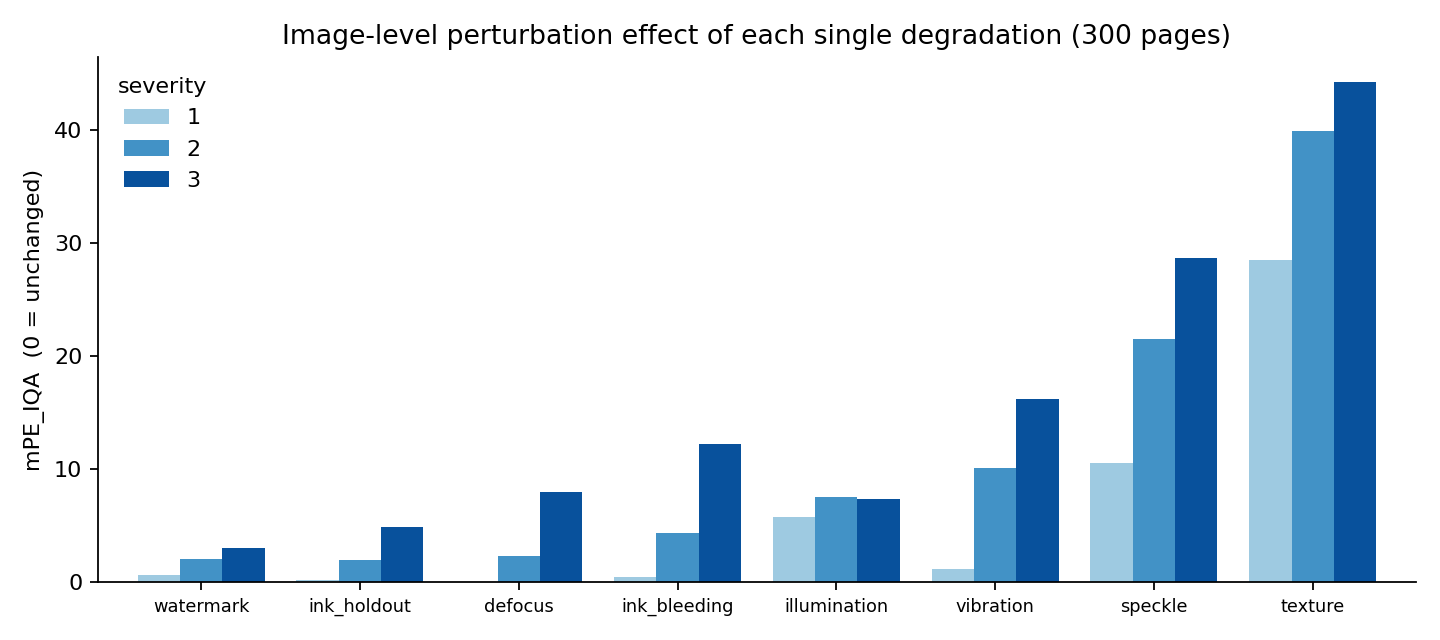

ms_ssim  cw_ssim  mPE_iqa
kind   severity                           
pair   1           0.943    0.829   11.404
       2           0.874    0.716   20.542
       3           0.819    0.641   26.974
single 1           0.971    0.911    5.904
       2           0.932    0.844   11.220
       3           0.896    0.793   15.566

In [13]:
# image damage per degradation (mPE from MS-SSIM and CW-SSIM)
show(R / "p2" / "image_quality" / "fig_iq_by_degradation.png", width=780)
iq = pd.read_csv(R / "p2" / "image_quality" / "iq_per_config.csv")
iq.groupby(["kind", "severity"])[["ms_ssim", "cw_ssim", "mPE_iqa"]].mean().round(3)

In [14]:
# RoDLA's robustness score mRD (lower is better), both page sets
named(pd.read_csv(R / "p2" / "evaluation" / "mrd.csv")).merge(
    named(pd.read_csv(RT / "p2" / "evaluation" / "mrd.csv")), on="model", suffixes=(" validation", " test")).sort_values("mRD validation")

,model,mRD validation,mRD test
10,YOLO26-l,7.745,6.694
7,YOLO26-m,7.801,6.833
8,YOLOv11-l,8.269,7.423
9,YOLOv11-m,8.342,7.613
5,Heron-101,8.760,8.315
0,Deformable DETR,8.796,7.679
4,Heron,8.914,8.295
3,Egret-xl,9.537,8.758
2,Egret-m,9.874,9.117
1,DETR,11.812,13.041


---
## P3. Main experiment: do degradations compound? (RQ1)

**Life-cycle stage:** statistical analysis.

| Part | By | Scripts |
|---|---|---|
| Paired page bootstrap and document bootstrap | Khizar | `p3_bootstrap.py`, `p3_jackknife.py`, `rdld/intervals.py` |
| Interaction terms, FDR, RQ1 analysis | Khizar | `p3_rq1_interaction.py` |
| Image quality versus accuracy | Alishba | `p3_iq_vs_accuracy.py` |
| Composition-order check | Alishba | `p3_order_check.py` |

For a pair A+B the interaction compares the pair's loss with what the two singles predict, under an additive null
($I_{add}$, mAP points) and a multiplicative null ($I_{mult}$, points of clean mAP). A positive value means the pair
hurts more than predicted. Each value gets a bootstrap p-value, and the 84 pairs of each detector are corrected with
Benjamini–Hochberg (Algorithm 2 in the paper).

`scripts/p3_bootstrap.py`, lines 52–66 (two-stage document resampling, stratified by category)

```python
def doc_resamples(n_boot, seed=20261108):
    """Two-stage resamples stratified by document category, padded with -1 to one length."""
    m = pd.read_csv(config.MANIFEST, dtype={"id": str})
    assert (m.index == m.id.astype(int)).all(), "manifest row order must match COCO image ids"
    strata = [[g.index.to_numpy() for _, g in s.groupby("original_filename")] for _, s in m.groupby("doc_category")]
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        pages = []
        for docs in strata:
            for d in rng.integers(0, len(docs), size=len(docs)):
                pages.append(rng.choice(docs[d], size=len(docs[d]), replace=True))
        out.append(np.concatenate(pages))
    width = max(map(len, out))
    return np.array([np.pad(s, (0, width - len(s)), constant_values=-1) for s in out])
```

`scripts/p3_rq1_interaction.py`, lines 91–108 (the two interaction terms on every resample)

```python
        for r in pairs.itertuples():
            ca, cb = f"{r.a}@{r.severity}", f"{r.b}@{r.severity}"
            xa, xb, xab = get(ca), get(cb), get(r.config)
            da, db, dab = 100 * (clean - xa), 100 * (clean - xb), 100 * (clean - xab)
            i_add = dab - da - db
            i_mult = 100 * ((xa / clean) * (xb / clean) - xab / clean)
            row = {"model": m, "severity": r.severity, "a": r.a, "b": r.b, "config": r.config,
                   "mAP_clean": float(clean[0]), "D_a": float(da[0]), "D_b": float(db[0]),
                   "D_ab": float(dab[0]),
                   "pred_additive": float(da[0] + db[0]),
                   "pred_multiplicative": float(100 * clean[0] * (1 - (xa[0] / clean[0]) * (xb[0] / clean[0]))),
                   "pred_max": float(max(da[0], db[0]))}
            for name, v in (("add", i_add), ("mult", i_mult)):
                pt, lo, hi, p = boot_stats(v)
                blo, bhi = intervals.bca_ci(v)
                row.update({f"I_{name}": pt, f"I_{name}_lo": lo, f"I_{name}_hi": hi, f"p_{name}": p,
                            f"I_{name}_lo_bca": blo, f"I_{name}_hi_bca": bhi})
            rows.append(row)
```

`scripts/p3_rq1_interaction.py`, lines 62–70 (Benjamini–Hochberg)

```python
def bh(p):
    p = np.asarray(p, float)
    n = len(p)
    order = np.argsort(p)
    q = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(q, 1)
    return out
```

In [15]:
# Table II of the paper, recomputed from the saved interaction tables (control pairs removed)
def table2(root):
    t = pd.read_csv(root / "p3" / "rq1" / "rq1_interactions.csv")
    t = t[~((t.severity == 1) & ((t.a == "defocus") | (t.b == "defocus")))]
    c = lambda col: "/".join(str((t[col] == k).sum()) for k in ["super", "sub", "n.s."])
    return {"cells": len(t), "additive super/sub/n.s.": c("class_add"), "multiplicative super/sub/n.s.": c("class_mult"),
            "super under both": int(((t.class_add == "super") & (t.class_mult == "super")).sum())}

pd.DataFrame({"validation, page": table2(R), "validation, document": table2(RD),
              "test, page": table2(RT), "test, document": table2(RTD)}).T

,cells,additive super/sub/n.s.,multiplicative super/sub/n.s.,super under both
"validation, page",847,87/208/552,228/105/514,83
"validation, document",847,60/167/620,188/75/584,57
"test, page",847,111/265/471,299/134/414,111
"test, document",847,62/200/585,219/86/542,61


In [16]:
# the negative control: defocus at severity 1 changes no pixel, so its 77 interactions must be exactly zero
t = pd.read_csv(R / "p3" / "rq1" / "rq1_interactions.csv")
ctl = t[(t.severity == 1) & ((t.a == "defocus") | (t.b == "defocus"))]
print(f"control cells: {len(ctl)}   largest |I_add|: {ctl.I_add.abs().max():.2e}   largest |I_mult|: {ctl.I_mult.abs().max():.2e}")

# median I_mult per detector: positive for every detector on both page sets
med = lambda r: named(pd.read_csv(r / "p3" / "rq1" / "rq1_interactions.csv").drop(ctl.index)).groupby("model").I_mult.median()
pd.DataFrame({"median I_mult, validation": med(R), "median I_mult, test": med(RT)}).round(2)

control cells: 77   largest |I_add|: 0.00e+00   largest |I_mult|: 0.00e+00


,"median I_mult, validation","median I_mult, test"
model,,
DETR,0.47,0.96
Deformable DETR,0.21,0.45
Egret-m,1.48,0.24
Egret-xl,1.20,2.00
Heron,1.09,0.87
Heron-101,0.85,0.56
RF-DETR,0.44,1.00
YOLO26-l,0.70,0.73
YOLO26-m,0.56,0.81


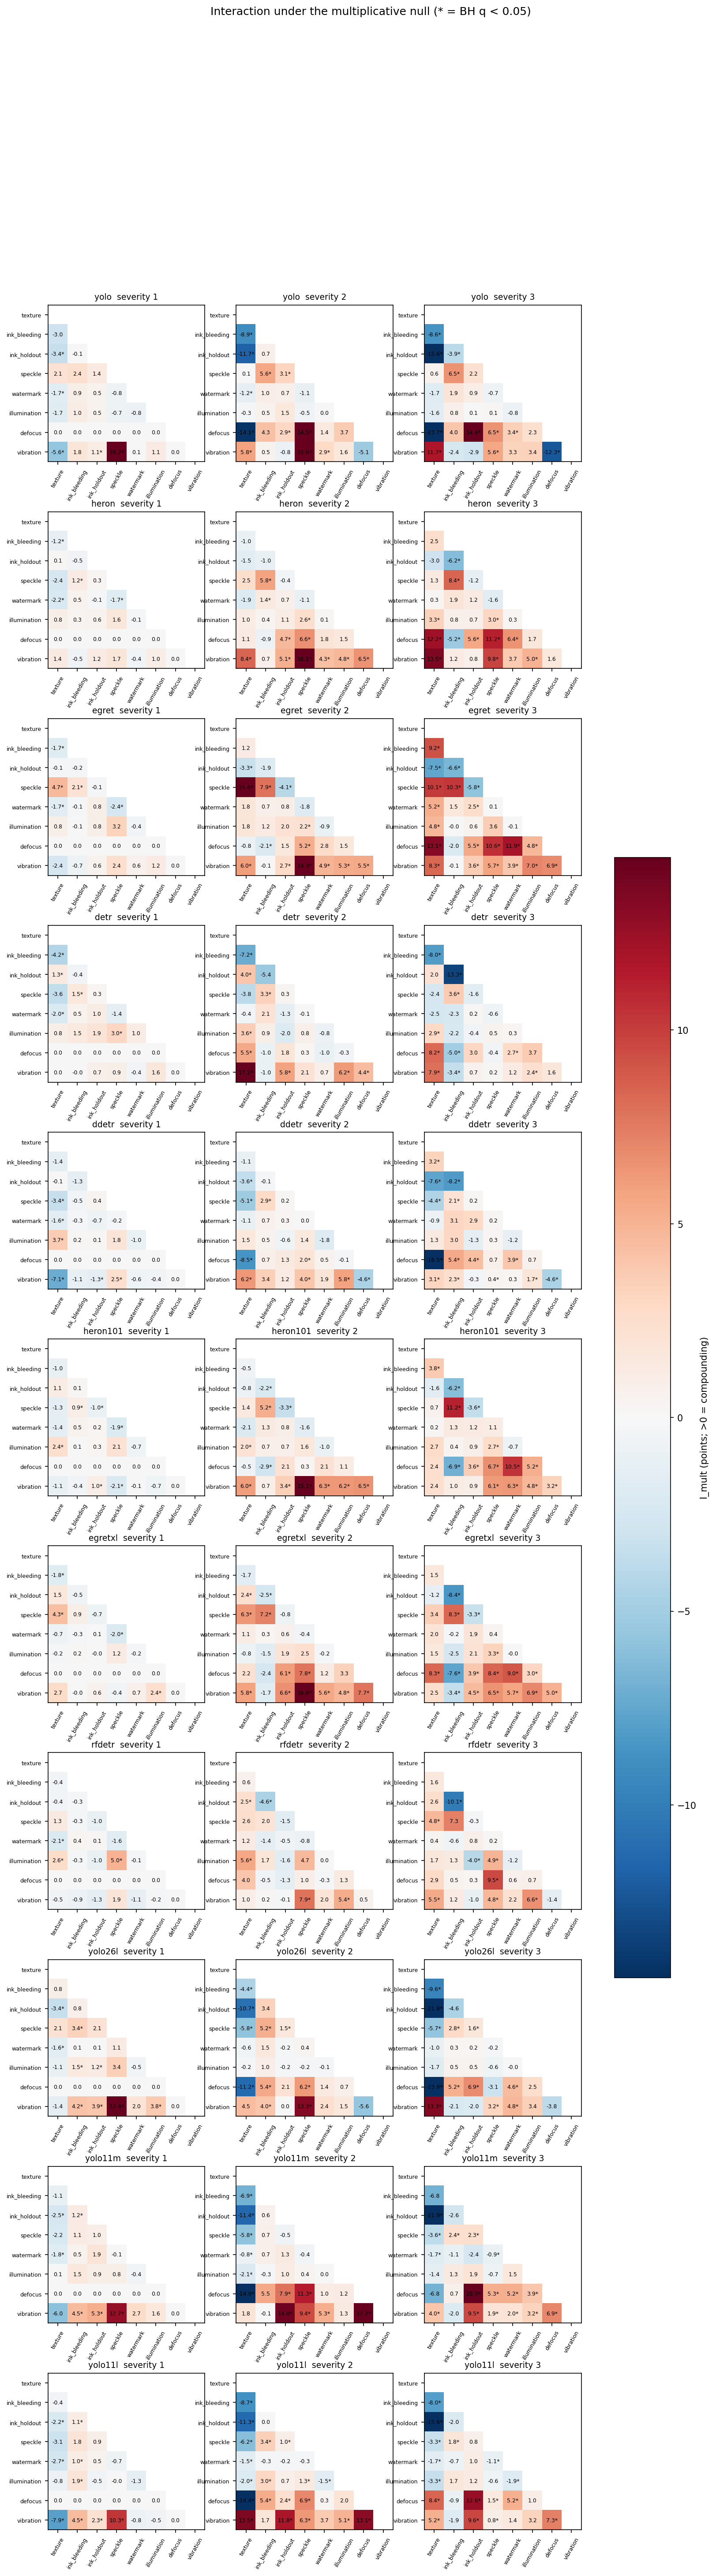

In [17]:
# mean I_mult per pair, averaged over detectors, at each severity (red = worse than predicted)
show(R / "p3" / "rq1" / "fig_interaction_heatmaps.png", width=560, max_side=2400)

In [18]:
# how well the singles predict the pair: the multiplicative rule has the lowest error for every detector
p = named(pd.read_csv(R / "p3" / "rq1" / "rq1_prediction_from_singles.csv"))
p.pivot(index="model", columns="predictor", values="MAE_pts").round(2)

predictor,additive,max,multiplicative
model,,,
DETR,3.43,2.71,1.34
Deformable DETR,5.13,2.02,1.51
Egret-m,2.51,4.58,2.22
Egret-xl,2.67,4.18,1.93
Heron,2.05,3.65,1.83
Heron-101,2.52,3.74,1.69
RF-DETR,1.87,2.46,1.01
YOLO26-l,4.08,2.91,2.48
YOLO26-m,4.37,3.54,2.70


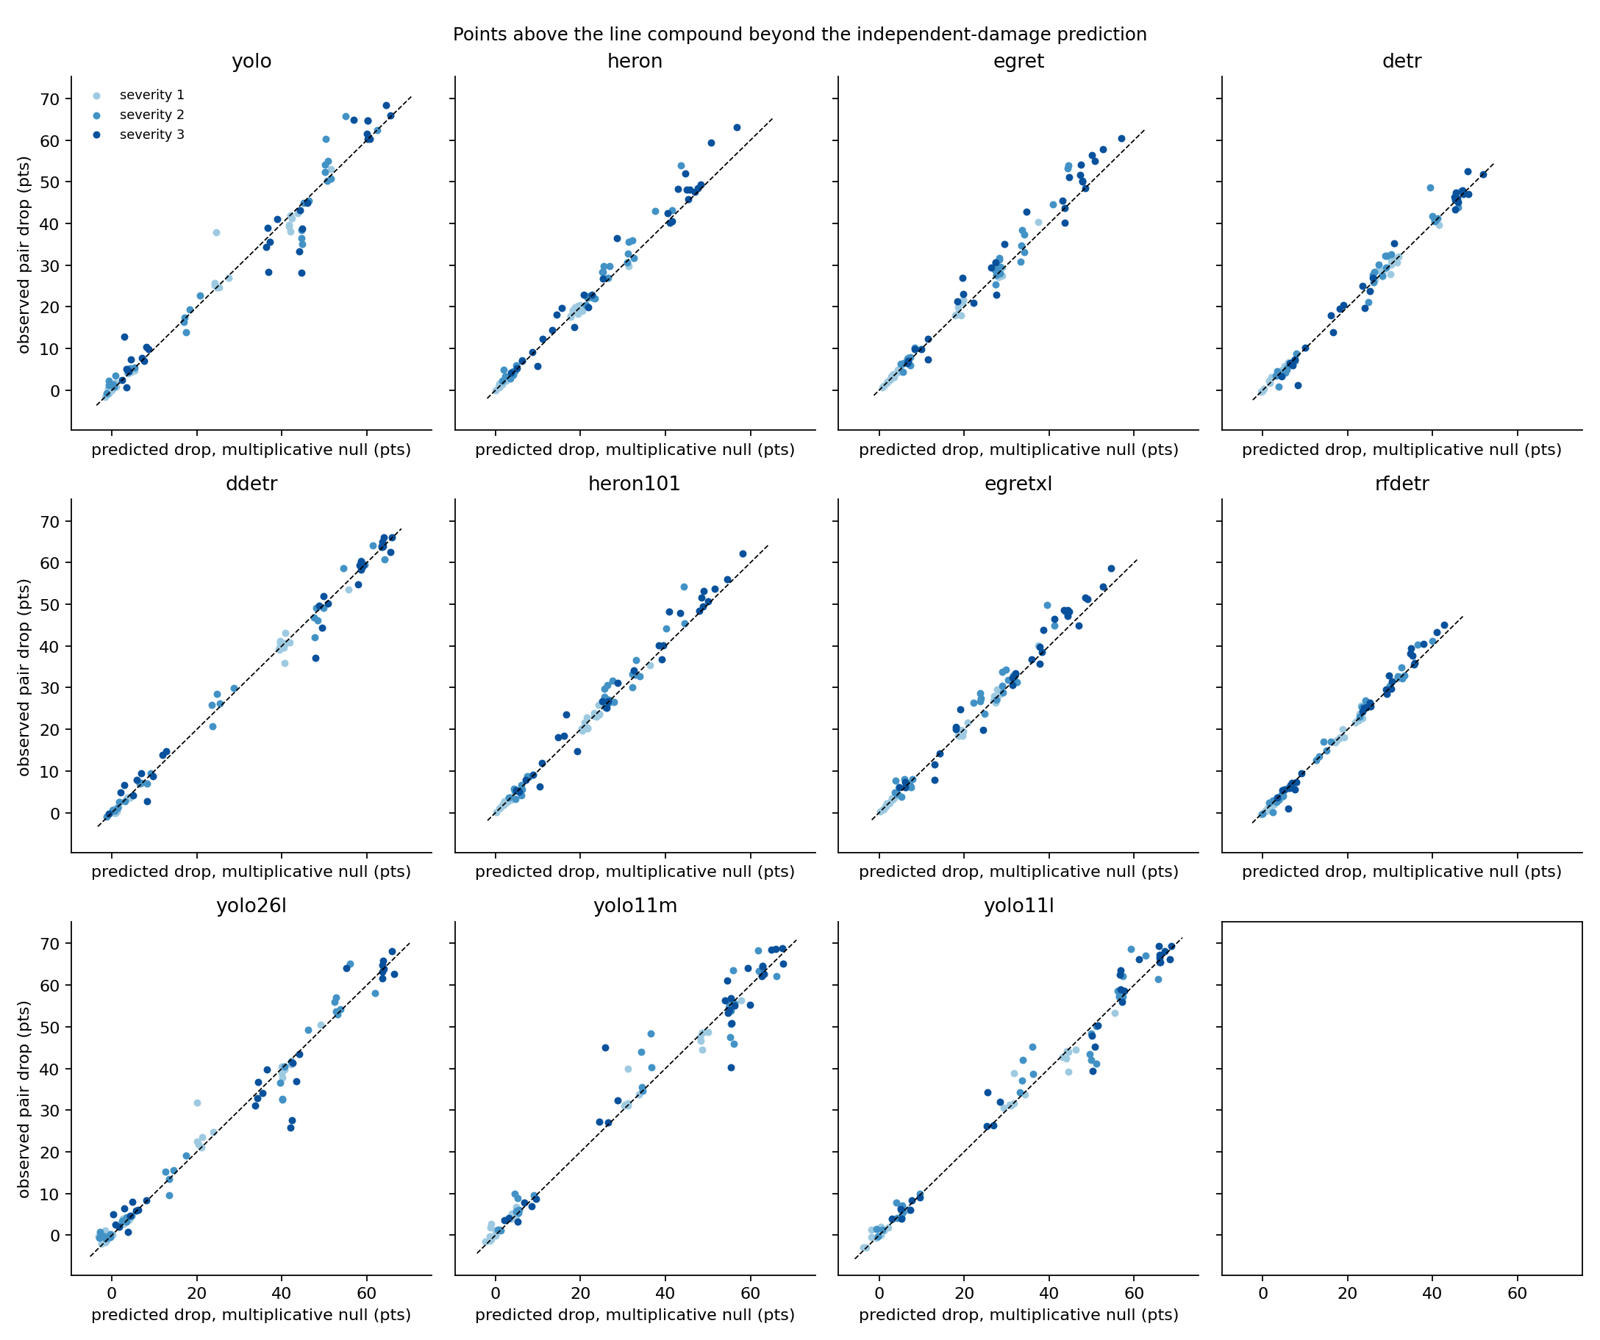

In [19]:
show(R / "p3" / "rq1" / "fig_observed_vs_predicted.png", width=820)

In [20]:
# composition order: reversing the order of a pair changes mAP very little, except for texture
o = pd.read_csv(R / "p3" / "order" / "order_effect.csv")
o["texture_pair"] = o.forward.str.contains("texture")
o.groupby("texture_pair").agg(tests=("significant", "size"), significant=("significant", "sum"),
                              median_abs_change=("delta_mAP_rev_minus_fwd", lambda x: x.abs().median()),
                              max_abs_change=("delta_mAP_rev_minus_fwd", lambda x: x.abs().max())).round(2)

,tests,significant,median_abs_change,max_abs_change
texture_pair,,,,
False,231,101,0.34,6.41
True,77,63,3.24,23.43


In [21]:
# does pixel damage explain detector damage? the pixel-level interaction barely tracks the detector interaction
named(pd.read_csv(R / "p3" / "iq_vs_accuracy" / "interaction_correlation.csv")).round(3)

,model,n_pairs,spearman_I_img_vs_I_mult,p,share_pairs_I_img_positive
0,Deformable DETR,84,0.077,0.486,0.179
1,DETR,84,0.064,0.560,0.179
2,Egret-m,84,-0.325,0.003,0.179
3,Egret-xl,84,-0.251,0.021,0.179
4,Heron,84,-0.261,0.017,0.179
5,Heron-101,84,-0.174,0.113,0.179
6,RF-DETR,84,-0.181,0.100,0.179
7,YOLO26-m,84,0.187,0.089,0.179
8,YOLOv11-l,84,0.101,0.362,0.179
9,YOLOv11-m,84,0.101,0.362,0.179


---
## P4. Rankings and per-region analysis (RQ3)

**Life-cycle stage:** statistical analysis and error analysis.

| Part | By | Scripts |
|---|---|---|
| Ranking stability, Kendall τ gap, robustness rankings | Khizar | `p4_rq3_rankings.py`, `p4_rq3_robustness.py` |
| Seed replicate analysis | Khizar | `p4_seed_stability.py` |
| Second-seed degraded images | Alishba | `p4_seed_replicate.py` |
| Per-class AP under degradation | Alishba | `p4_per_class.py` |
| Structural error rates (merge, split, miss) | Alishba | `p4_structural_errors.py` |

In every condition the eleven detectors are ranked and compared with the clean ranking by Kendall's τ. The τ gap is
the mean τ over singles minus the mean over pairs. Every ground-truth region is also labelled correct, misclassified,
merged, split, poorly localised or missed.

`scripts/p4_rq3_robustness.py`, lines 51–56 (Kendall τ against the clean order, on every resample)

```python
def tau_vs(A, B):
    """Kendall tau between two orderings, per resample. A, B: (n_models, n_resamples)."""
    idx = np.array(list(combinations(range(A.shape[0]), 2)))
    sa = np.sign(A[idx[:, 0]] - A[idx[:, 1]])
    sb = np.sign(B[idx[:, 0]] - B[idx[:, 1]])
    return (sa * sb).mean(axis=0)
```

`scripts/p4_structural_errors.py`, lines 68–101 (structural error labels for one page)

```python
def classify_page(gt_boxes, gt_cls, pr_boxes, pr_cls, pr_score):
    G, P = len(gt_boxes), len(pr_boxes)
    kinds = np.array(["missed"] * G, dtype=object)
    pr_kind = np.array(["ok"] * P, dtype=object)
    if P == 0:
        return kinds, pr_kind
    iou, ioa_g, ioa_p = overlaps(gt_boxes, pr_boxes)
    # one-to-one greedy matching by score, class-agnostic, IoU >= 0.5
    match_of_pred, gt_taken = -np.ones(P, int), np.zeros(G, bool)
    for j in np.argsort(-pr_score):
        cand = np.where((iou[:, j] >= 0.5) & ~gt_taken)[0]
        if len(cand):
            i = cand[np.argmax(iou[cand, j])]
            match_of_pred[j], gt_taken[i] = i, True
    for j, i in enumerate(match_of_pred):
        if i >= 0:
            kinds[i] = "correct" if pr_cls[j] == gt_cls[i] else "misclassified"
    for i in range(G):
        if kinds[i] != "missed":
            continue
        covers = np.where(ioa_g[i] >= 0.5)[0]
        merged = any((ioa_g[:, j] >= 0.5).sum() >= 2 for j in covers)
        inside = np.where((ioa_p[i] >= 0.7) & (iou[i] < 0.5))[0]
        best = iou[i].max()
        kinds[i] = ("merged" if merged else "split" if len(inside) >= 2
                    else "localisation" if best >= 0.1 else "missed")
    for j in range(P):
        if match_of_pred[j] >= 0:
            continue
        if (iou[:, j] >= 0.5).any():
            pr_kind[j] = "duplicate"
        elif iou[:, j].max() < 0.1 and ioa_p[:, j].max() < 0.5:
            pr_kind[j] = "hallucination"
    return kinds, pr_kind
```

In [22]:
# the tau gap, singles minus pairs, with page-bootstrap and BCa intervals
g = lambda r: pd.read_csv(r / "p4" / "rq3_robustness" / "tau_gap.csv").set_index("detectors")
pd.concat({"validation": g(R), "test": g(RT)})[["n_detectors", "tau_single", "tau_pair", "gap", "lo", "hi", "lo_bca", "hi_bca"]].round(3)

n_detectors  tau_single  tau_pair    gap     lo     hi  lo_bca  hi_bca
           detectors                                                                                     
validation all                              11       0.494     0.222  0.272  0.195  0.292   0.248   0.311
           distinct_architectures            6       0.670     0.420  0.250  0.178  0.284   0.206   0.295
           original3                         3       0.681     0.429  0.253  0.053  0.290   0.157   0.297
           without_rfdetr                   10       0.469     0.195  0.274  0.183  0.293   0.250   0.312
           first8                            8       0.671     0.464  0.207  0.131  0.243   0.153   0.258
test       all                              11       0.589     0.323  0.266  0.231  0.287   0.244   0.302
           distinct_architectures            6       0.739     0.510  0.229  0.191  0.241   0.218   0.256
           original3                         3       0.710     0.472  0.238  0.192  0.296   0.192   0.294
           without_rfdetr                   10       0.563     0.301  0.262  0.218  0.286   0.234   0.304
           first8                            8       0.671     0.466  0.205  0.176  0.232   0.176   0.232

In [23]:
# at equal damage the pair effect is small and changes sign across methods, so no claim is made on it
pd.read_csv(R / "p4" / "rq3_robustness" / "pair_effect_at_equal_damage.csv").round(3)

,detectors,estimator,pair_effect_at_equal_damage,lo,hi,excludes_zero,lo_bca,hi_bca
0,all,linear in retention,0.031,-0.012,0.053,False,0.005,0.065
1,all,within retention bands,0.008,-0.030,0.031,False,-0.011,0.040
2,distinct_architectures,linear in retention,0.042,0.009,0.078,True,0.006,0.075
3,distinct_architectures,within retention bands,0.018,-0.022,0.067,False,-0.030,0.056
4,original3,linear in retention,0.041,-0.072,0.096,False,-0.206,0.070
5,original3,within retention bands,-0.007,-0.061,0.101,False,-0.213,0.029
6,without_rfdetr,linear in retention,0.022,-0.025,0.052,False,-0.018,0.056
7,without_rfdetr,within retention bands,0.020,-0.025,0.040,False,0.003,0.056
8,first8,linear in retention,0.051,-0.003,0.067,False,0.034,0.082
9,first8,within retention bands,0.044,-0.012,0.062,False,0.026,0.082


In [24]:
# robustness rankings: retention over singles, retention over pairs, and RoDLA's mRD give different winners
b = named(pd.read_csv(R / "p4" / "rq3" / "benchmark_rankings.csv"))
r = b.pivot(index="model", columns="benchmark", values="rank")
mrd = named(pd.read_csv(R / "p2" / "evaluation" / "mrd.csv")).set_index("model").mRD.rank().astype(int).rename("mRD rank")
r.join(mrd).sort_values(r.columns[0])

,pair,single,mRD rank
model,,,
Heron,1,1,7
Heron-101,2,2,5
RF-DETR,3,3,11
YOLO26-l,4,4,1
Egret-xl,5,5,8
YOLO26-m,6,6,2
Egret-m,7,7,9
DETR,8,8,10
Deformable DETR,9,9,6


In [25]:
# failure type on severity-3 pairs: change in merged minus change in missed regions (points; positive = mostly merging)
s = pd.read_csv(R / "p4" / "structural" / "structural_vs_clean.csv")
f = s[(s.kind == "pair") & (s.severity == 3)].groupby("model").apply(lambda x: x.gt_merged.mean() - x.gt_missed.mean(), include_groups=False)
named(f.rename("merged minus missed").reset_index()).set_index("model").sort_values("merged minus missed").round(1)

,merged minus missed
model,
YOLOv11-l,-30.4
YOLOv11-m,-28.1
RF-DETR,-15.9
YOLO26-m,-12.4
YOLO26-l,-8.1
Deformable DETR,-7.1
DETR,-4.6
Heron-101,15.7
Heron,16.5


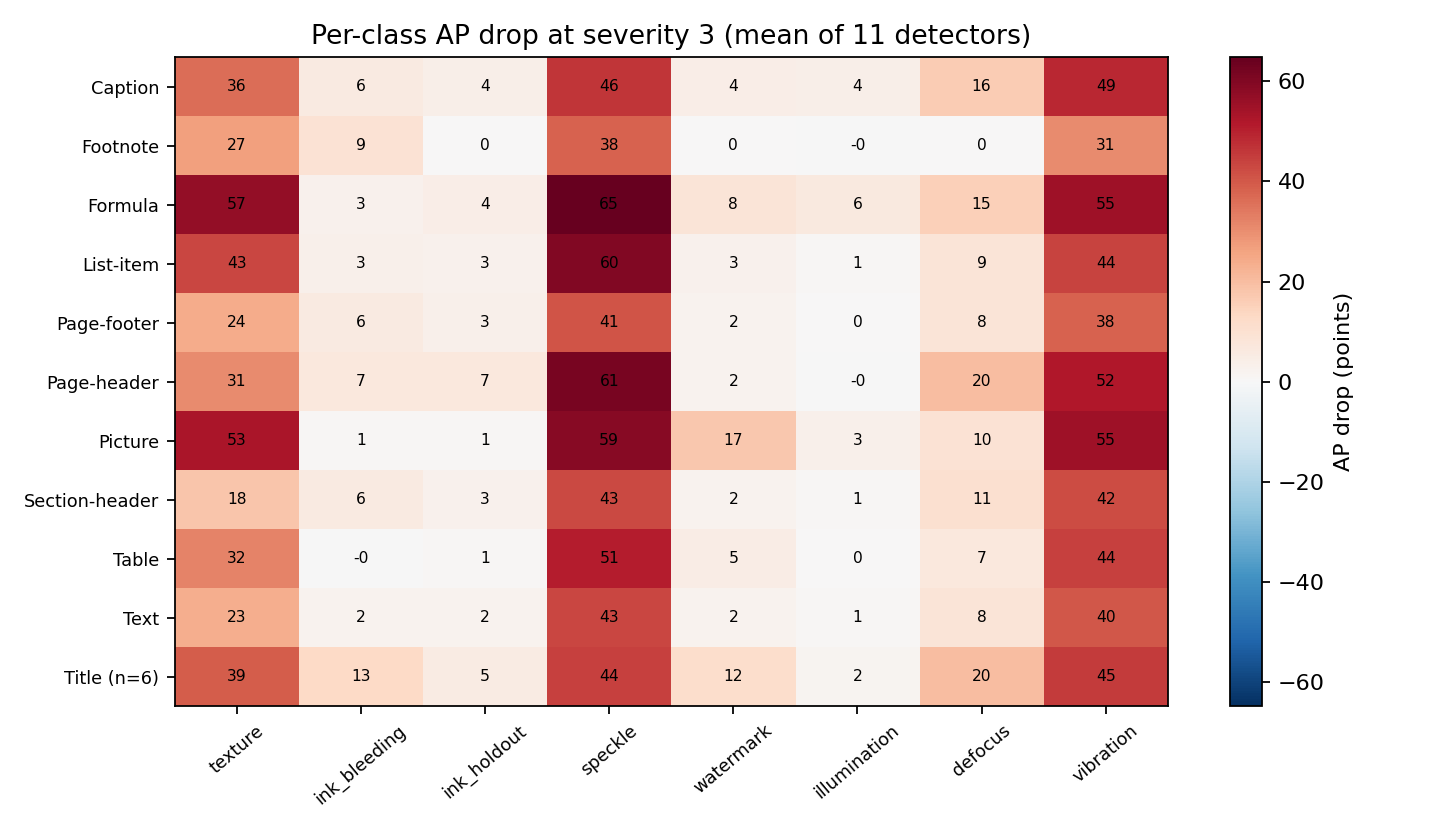

,cls,mean_drop_sev3_pts,median_I_mult_sev2,median_I_mult_sev3,share_small_boxes,n_boxes
0,Caption,20.66,1.07,1.15,0.14,66
1,Footnote,13.15,1.26,0.87,0.00,41
2,Formula,26.68,0.04,0.66,0.00,50
3,List-item,20.62,0.66,1.59,0.03,380
4,Page-footer,15.33,0.97,0.53,0.70,215
5,Page-header,22.43,0.64,0.59,0.21,312
6,Picture,24.71,1.10,1.79,0.00,119
7,Section-header,15.71,1.05,1.01,0.17,578
8,Table,17.45,1.25,2.14,0.00,102
9,Text,15.39,1.41,1.55,0.02,1661


In [26]:
show(R / "p4" / "per_class" / "fig_class_by_degradation.png", width=820)
pd.read_csv(R / "p4" / "per_class" / "class_vulnerability.csv").round(2)

In [27]:
# second degradation seed: interactions move far less than the page-sampling noise
named(pd.read_csv(R / "p4" / "seeds" / "seed_summary.csv")).round(3)

,model,n_pairs,spearman_I_seed0_vs_seed1,mean_abs_diff,mean_ci_halfwidth,ratio_seed_noise_to_page_noise,call_agreement,opposite_significant_calls
0,Deformable DETR,28,0.916,0.894,2.228,0.401,0.929,0
1,DETR,28,0.900,0.778,2.826,0.275,0.893,0
2,Egret-m,28,0.944,1.026,2.477,0.414,0.821,0
3,Egret-xl,28,0.963,0.922,2.518,0.366,0.714,0
4,Heron,28,0.901,0.800,2.239,0.357,0.893,0
5,Heron-101,28,0.915,0.713,1.977,0.361,0.929,0
6,RF-DETR,28,0.885,0.797,2.573,0.310,0.893,0
7,YOLO26-m,28,0.968,0.690,2.507,0.275,0.821,0
8,YOLOv11-l,28,0.928,1.068,2.661,0.401,0.750,0
9,YOLOv11-m,28,0.951,0.944,3.109,0.304,0.821,0


---
## P5. Downstream link (RQ2)

**Life-cycle stage:** evaluation against the end use.

| Part | By | Scripts |
|---|---|---|
| OCR pipeline, WER and text measures | Alishba | `p5_ocr_downstream.py` |
| Utility-weighted mAP, weight sensitivity, mAP versus downstream | Khizar | `p5_rq2_metric_validity.py` |

Tesseract reads every page once per condition. The same words are read through the ground-truth regions (reference
text) and through each detector's regions with score at least 0.5 (detector text), so any difference in text quality
comes from the layout alone.

`scripts/p5_ocr_downstream.py`, lines 105–129 (reading words through regions, and word error rate)

```python
def read(words, boxes, classes):
    """Text a region pipeline produces: regions in XY-cut order, words by centre."""
    keep = [i for i, c in enumerate(classes) if c != PICTURE]
    if not keep or not words:
        return []
    b = boxes[keep]
    text = []
    for r in xycut(b):
        x1, y1, x2, y2 = b[r]
        inside = [w for w in words if x1 <= w[1] <= x2 and y1 <= w[2] <= y2]
        inside.sort(key=lambda w: (round(w[2] / 8), w[1]))  # lines, then left to right
        text += [w[0] for w in inside]
    return text


def wer(ref, hyp):
    if not ref:
        return float(len(hyp) > 0)
    prev = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        cur = [i] + [0] * len(hyp)
        for j, h in enumerate(hyp, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (r != h))
        prev = cur
    return prev[-1] / len(ref)
```

`scripts/p5_rq2_metric_validity.py`, lines 128–137 (correlation within a condition)

```python
    within = []
    D = J.copy()
    for col in layout + targets:
        D[col] = D[col] - D.groupby("config")[col].transform("mean")
    for a in layout:
        for t in targets:
            h = D[[a, t]].dropna()
            within.append({"layout_metric": a, "downstream": t, "n": len(h),
                           "spearman_within_condition": float(spearmanr(h[a], h[t]).statistic)})
    WC = pd.DataFrame(within)
```

In [28]:
# word error rate per detector on the clean pages, and on severity-2 singles and pairs (validation)
d = named(pd.read_csv(R / "p5" / "downstream" / "downstream_configs.csv"))
d.pivot_table(index="model", columns="kind", values="WER", aggfunc="mean")[["clean", "single", "pair"]].sort_values("clean").round(3)

kind,clean,single,pair
model,,,
YOLO26-m,0.022,0.103,0.234
YOLO26-l,0.035,0.131,0.256
YOLOv11-l,0.041,0.180,0.339
Deformable DETR,0.058,0.257,0.445
YOLOv11-m,0.063,0.197,0.364
RF-DETR,0.084,0.151,0.232
Heron-101,0.098,0.133,0.181
Egret-m,0.102,0.155,0.229
Egret-xl,0.105,0.153,0.220


In [29]:
# Spearman correlation of each layout metric with each text measure, condition means removed
w = pd.read_csv(R / "p5" / "rq2" / "within_condition_correlation.csv")
w.pivot(index="layout_metric", columns="downstream", values="spearman_within_condition").round(2)

downstream,WER,table_recall,text_precision,text_recall
layout_metric,,,,
UW_mAP,-0.73,0.38,-0.18,0.60
gt_correct,-0.63,0.25,-0.69,0.89
mAP,-0.73,0.39,-0.10,0.55
mAP50,-0.66,0.22,-0.40,0.68
mAP75,-0.64,0.45,0.13,0.38
pred_duplicate,-0.32,0.04,-0.91,0.70
structural_error,0.19,0.10,-0.08,-0.06


conditions where the best detector by mAP is also the best by WER: 15 of 37


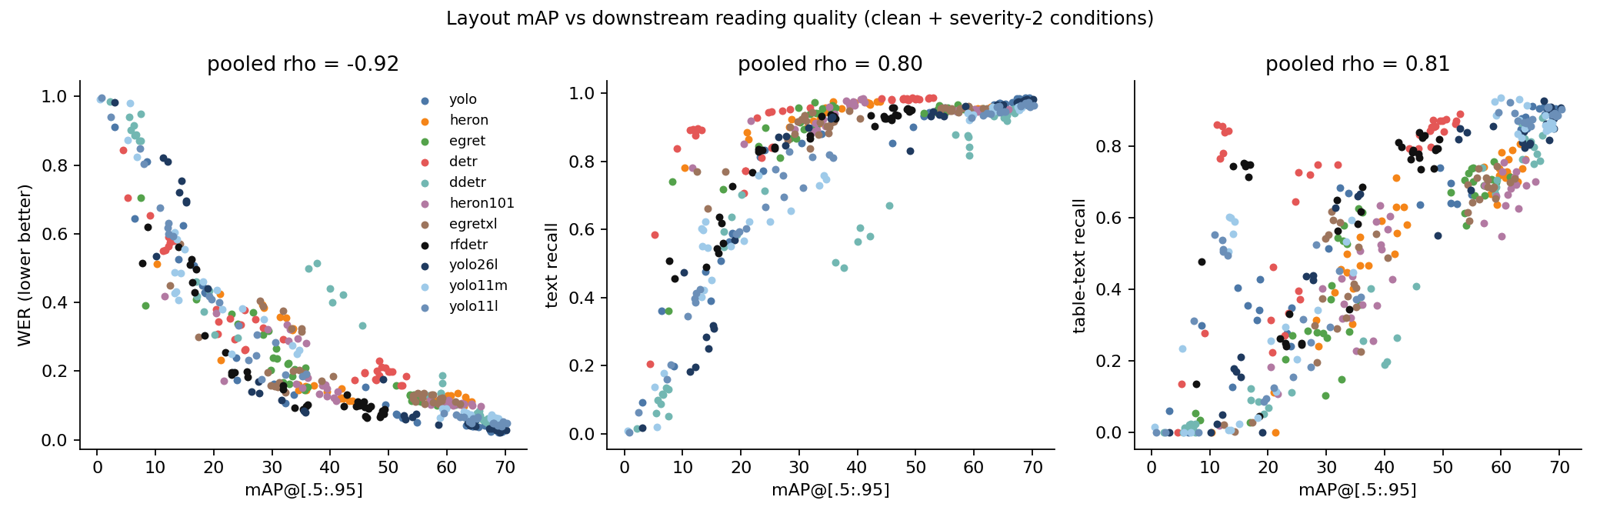

In [30]:
a = pd.read_csv(R / "p5" / "rq2" / "ranking_agreement.csv")
print(f"conditions where the best detector by mAP is also the best by WER: {a.agree_best.sum()} of {len(a)}")
show(R / "p5" / "rq2" / "fig_map_vs_downstream.png", width=880)

---
## P6. Results synthesis and paper

**Life-cycle stage:** communication. **By:** Khizar and Alishba together (`docs/phases/P6_writeup/RESULTS_SYNTHESIS.md`
and the research paper).

| RQ | Answer | Where it is shown above |
|---|---|---|
| RQ1 | For every detector the typical pair removes more accuracy than a multiplicative combination of the two singles predicts, and strongly super-additive pairs occur for ten of eleven detectors on the validation pages and all eleven on the test pages. | P3 |
| RQ3 | Rankings agree far less with the clean ranking under pairs than under singles (a τ gap of about 0.27 on both page sets), but at equal damage no consistent pair effect remains. The robustness metric (retention or mRD) changes the winner more than pairing does. | P4 |
| RQ2 | mAP tracks word error rate within a condition, but it does not see duplicated detections, and duplicates drive text precision. | P5 |

Every claim holds under both the page bootstrap and the document bootstrap, and on both page sets.

---
## P7. Extension and checks

**Life-cycle stage:** validating the findings.

| Part | By | Scripts |
|---|---|---|
| Three more YOLO models, Heron-101, Egret-xl, DETR, Deformable DETR | Khizar | `rdld/detectors.py` |
| RF-DETR fine-tuning | Khizar | `p7_finetune_rfdetr.py` |
| RF-DETR training data, with leakage checks | Alishba | `p7_prepare_train_data.py` |
| Official test-split pages | Alishba | `p0_prepare_doclaynet.py` (split option) |
| Leakage, selection-set and Title checks | Khizar | `p7_test_split_leakage.py`, `p7_select_vs_test.py`, `p7_title_sensitivity.py` |
| RQ1 at equal predicted damage | Khizar | `p7_rq1_damage_bands.py` |

The study grew from three detectors to eleven, and the whole pipeline was repeated on the official test split. The cells
below are the checks we ran on the main results.

`scripts/p7_rq1_damage_bands.py`, lines 77–86 (interaction inside bands of equal predicted damage)

```python
    edges = np.quantile(P[0], np.linspace(0, 1, N_BANDS + 1))
    band = np.clip(np.searchsorted(edges, P[0], side="right") - 1, 0, N_BANDS - 1)
    rows, drows = [], []
    for k in range(N_BANDS):
        sel = band == k
        v = I[:, sel].mean(1)
        pt, lo, hi = intervals.percentile_ci(v)
        rows.append({"band": k + 1, "P_from": edges[k], "P_to": edges[k + 1], "n_cells": int(sel.sum()),
                     "P_mean": float(P[0, sel].mean()), "I_mult_mean": pt, "lo": lo, "hi": hi,
                     "p": intervals.boot_p(v), "share_cells_positive": float((I[0, sel] > 0).mean())})
```

In [31]:
# no test-split document appears in the validation split or in RF-DETR's training data
pd.read_csv(RT / "p7" / "test_split_leakage.csv")

,against,n_pages,n_docs,test_docs_shared,test_pages_shared
0,RF-DETR train shards (12 of 72),11563,1431,0,0
1,validation split (all 7 shards),6489,160,0,0


In [32]:
# RF-DETR fine-tuning summary (no released layout checkpoint exists, so we trained one)
pd.read_csv(R / "p7" / "finetune_summary.csv")

,base,resolution,train_pages,select_pages,epochs_run,best_epoch,best_select_mAP,train_hours
0,Roboflow/rf-detr-medium,672,11526,600,12,11,0.574,12.378


In [33]:
# mean I_mult inside five bands of predicted damage: it stays positive even where the two singles barely hurt
bands = lambda r: pd.read_csv(r / "p7" / "rq1_damage" / "damage_bands.csv").set_index("band")[["P_from", "P_to", "I_mult_mean", "lo", "hi"]]
pd.concat({"validation, page": bands(R), "validation, document": bands(RD), "test, page": bands(RT), "test, document": bands(RTD)}, axis=1).round(2)

validation, page                                validation, document                                test, page                                 \
               P_from   P_to I_mult_mean    lo    hi               P_from   P_to I_mult_mean    lo    hi     P_from   P_to I_mult_mean    lo    hi   
band                                                                                                                                                 
1               -5.31   7.25        0.99  0.51  1.36                -5.31   7.25        0.99  0.41  1.32      -1.94   7.96        0.69  0.48  0.91   
2                7.25  30.26        0.23 -0.25  0.79                 7.25  30.26        0.23 -0.21  0.87       7.96  28.73        0.24 -0.08  0.62   
3               30.26  50.32        1.93  1.48  2.48                30.26  50.32        1.93  1.43  2.70      28.73  50.31        1.88  1.54  2.30   
4               50.32  73.05        0.49  0.00  1.09                50.32  73.05        0.49 -0.10  1.24      50.31  70.44        0.92  0.59  1.30   
5               73.05  99.49        1.62  1.20  2.35                73.05  99.49        1.62  1.21  2.69      70.44  99.25        1.93  1.59  2.35   

     test, document                                 
             P_from   P_to I_mult_mean    lo    hi  
band                                                
1             -1.94   7.96        0.69  0.40  0.98  
2              7.96  28.73        0.24 -0.15  0.84  
3             28.73  50.31        1.88  1.36  2.61  
4             50.31  70.44        0.92  0.36  1.70  
5             70.44  99.25        1.93  1.46  2.83

In [34]:
# Title has only 6 boxes on the validation pages: removing the class barely changes the tau gap
pd.read_csv(R / "p7" / "title_sensitivity" / "tau.csv").assign(gap=lambda x: x.single - x.pair).round(3)

,classes,single,pair,gap
0,all,0.494,0.222,0.272
1,noTitle,0.450,0.203,0.247


---
## Reproducing any number

- Every table above was read from a file under `RDLD_data/results/` (validation pages) or `RDLD_data_test/results/`
  (test pages). The script that wrote each file is named in the phase it belongs to.
- `python scripts/p0_download_data.py --models` downloads the DocLayNet files and every checkpoint at the revisions we
  used. `docs/PIPELINE.md` then gives the full run order, with the time each step took. `requirements.txt` pins the exact package
  versions, and the README lists the source and licence of every dataset and model.
- The written account of every number is in the phase notes, `docs/phases/P*/NOTES_khizar.md` and `NOTES_alishba.md`.